In [1]:
import tensorflow as tf

import xarray as xr
import numpy as np

import matplotlib.pyplot as plt

2025-09-09 11:35:06.761758: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
filename = "output_data/test_data.nc"

In [3]:
ds = xr.open_dataset(filename)

In [4]:
ds

<xarray.Dataset> Size: 57MB
Dimensions:   (time: 1152, lat: 32, lon: 32, altitude: 6)
Coordinates:
  * time      (time) datetime64[ns] 9kB 2022-11-28 ... 2022-12-30T23:50:00
  * altitude  (altitude) float64 48B 500.0 1e+03 1.5e+03 3e+03 5e+03 7.5e+03
  * lat       (lat) float64 256B -23.14 -23.12 -23.11 ... -22.68 -22.67 -22.65
  * lon       (lon) float64 256B -43.9 -43.87 -43.85 ... -43.1 -43.08 -43.05
Data variables:
    dbzh      (time, lat, lon, altitude) float64 57MB ...

In [5]:
from utils import prepare_data, mse

cfg = {
    "architecture": "DLinear",
    "seq_len": 10,
    "pred_len": 1
}

In [6]:
X = ds["dbzh"].values
X_test, y_test = prepare_data(X, cfg["seq_len"], cfg["pred_len"], cfg=cfg)

In [7]:
model_name = "DLinear_final_model"
exp_name = "test_run"

In [8]:
# Show model Curve
history = np.load(f"outputs/{model_name}_hist_{exp_name}.npy", allow_pickle=True).item()

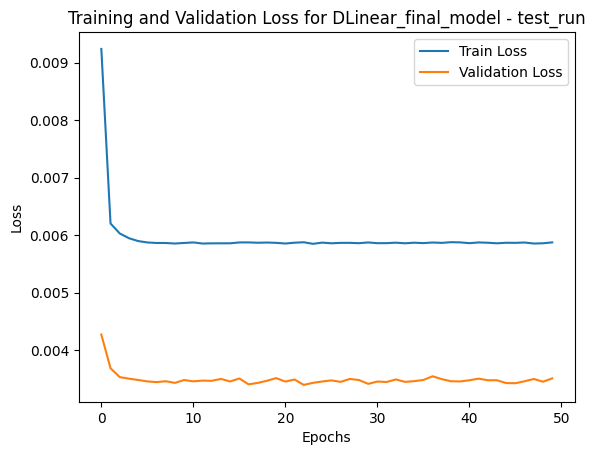

In [9]:
plt.plot(history['loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title(f'Training and Validation Loss for {model_name} - {exp_name}')
plt.show()

In [10]:
# Load model
# Make sure DLinear is defined or imported before this cell
from models.dlinear import DLinear  # or define DLinear in a previous cell

# Define seq_len (set to the value used during training, e.g., 96)
seq_len = 10
pred_len = 1
features = 6144

model_filename = f"outputs/{model_name}_{exp_name}.h5"
model = tf.keras.models.load_model(
	model_filename,
	custom_objects={
		'DLinear': lambda *args, **kwargs: DLinear(seq_len=seq_len, pred_len=pred_len, features=features, *args, **kwargs),
		'mse': tf.keras.metrics.mse
	}
)
model.summary()

W0000 00:00:1757428512.597655    1870 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "DLinear"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_40 (InputLayer)     │ (None, 10, 6144)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ d_linear_40 (DLinear)           │ (None, 1, 6144)        │            22 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24 (100.00 B)

 Trainable params: 22 (88.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [11]:
y_pred = model.predict(X_test).reshape(y_test.shape)

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [12]:
import joblib
scaler = joblib.load("scaler.save")

In [13]:
y_test = scaler.inverse_transform(y_test)
y_pred = scaler.inverse_transform(y_pred)

In [14]:
print(mse(y_test, y_pred))
print(np.std(y_pred - y_test))

194.00980548660127
13.923108086781014


In [15]:
y_test = y_test.reshape(-1, X.shape[1], X.shape[2], X.shape[3])
y_pred = y_pred.reshape(-1, X.shape[1], X.shape[2], X.shape[3])

In [16]:
y_test.shape

(1142, 32, 32, 6)

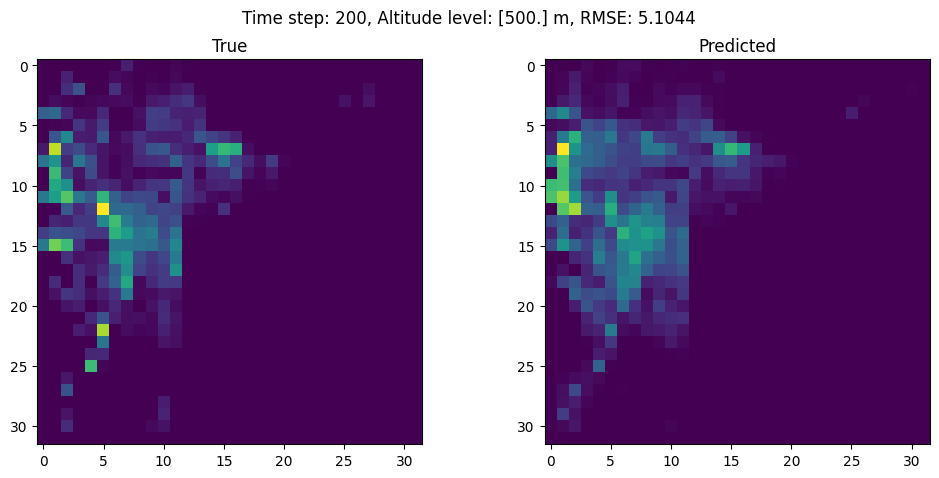

In [17]:
time = 200
alt = 0

sample_true = y_test[time, :, :, alt]
sample_pred = y_pred[time, :, :, alt]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(sample_true)
plt.title('True')

plt.subplot(1, 2, 2)
plt.imshow(sample_pred)
plt.title('Predicted')

plt.suptitle(f'Time step: {time}, Altitude level: {np.unique(ds["altitude"].values[alt])} m, RMSE: {np.sqrt(mse(sample_true, sample_pred)):.4f}')
plt.show()

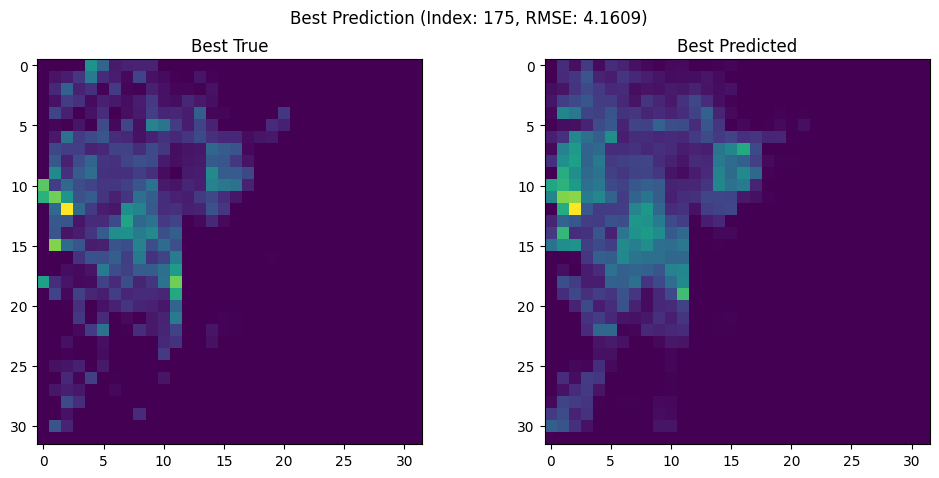

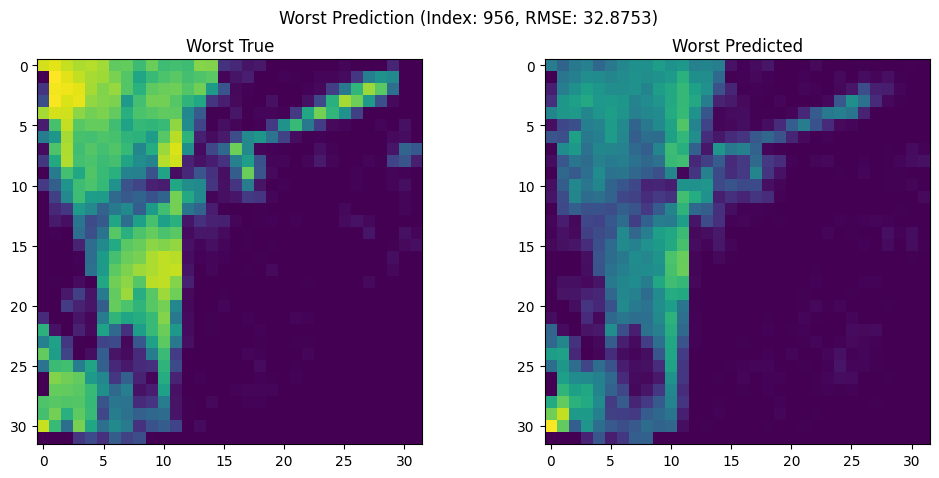

In [18]:
# Find best and worst predictions based on RMSE
rmses = np.sqrt(np.mean((y_test - y_pred) ** 2, axis=(1, 2, 3)))
best_idx = np.argmin(rmses)
worst_idx = np.argmax(rmses)

# Plot best prediction
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(y_test[best_idx, :, :, alt])
plt.title('Best True')
plt.subplot(1, 2, 2)
plt.imshow(y_pred[best_idx, :, :, alt])
plt.title('Best Predicted')
plt.suptitle(f'Best Prediction (Index: {best_idx}, RMSE: {
rmses[best_idx]:.4f})')
plt.show()

# Plot worst prediction
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(y_test[worst_idx, :, :, alt])
plt.title('Worst True')
plt.subplot(1, 2, 2)
plt.imshow(y_pred[worst_idx, :, :, alt])
plt.title('Worst Predicted')
plt.suptitle(f'Worst Prediction (Index: {worst_idx}, RMSE: {rmses[worst_idx]:.4f})')
plt.show()